In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np


(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = datasets.mnist.load_data()


mnist_train_images = mnist_train_images.reshape(-1, 28, 28, 1).astype('float32') / 255.0
mnist_test_images = mnist_test_images.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print("Train shape:", mnist_train_images.shape, "| Labels shape:", mnist_train_labels.shape)
print("Test shape :", mnist_test_images.shape, "| Labels shape:", mnist_test_labels.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (60000, 28, 28, 1) | Labels shape: (60000,)
Test shape : (10000, 28, 28, 1) | Labels shape: (10000,)


In [2]:
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = datasets.mnist.load_data()

mnist_train_images = mnist_train_images.reshape(-1, 28, 28, 1).astype('float32') / 255.0
mnist_test_images = mnist_test_images.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print("Train shape:", mnist_train_images.shape, "Labels shape:", mnist_train_labels.shape)
print("Test shape :", mnist_test_images.shape, "Labels shape:", mnist_test_labels.shape)

Train shape: (60000, 28, 28, 1) Labels shape: (60000,)
Test shape : (10000, 28, 28, 1) Labels shape: (10000,)


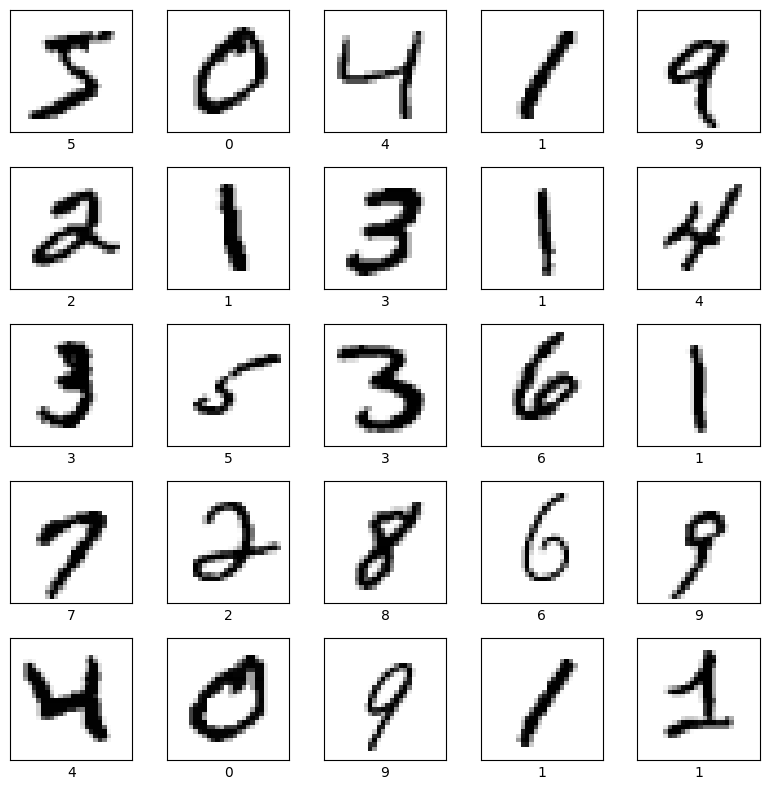

In [3]:
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(mnist_train_images[i].squeeze(), cmap=plt.cm.binary)
    plt.xlabel(str(mnist_train_labels[i]))
plt.tight_layout()
plt.show()

In [4]:
model_mnist = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_mnist.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_mnist.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,706 (366.04 KB)

 Trainable params: 93,514 (365.29 KB)

 Non-trainable params: 192 (768.00 B)

In [5]:
history_mnist = model_mnist.fit(
    mnist_train_images, mnist_train_labels,
    epochs=8,
    batch_size=64,
    validation_data=(mnist_test_images, mnist_test_labels),
    verbose=1
)

mnist_loss, mnist_acc = model_mnist.evaluate(mnist_test_images, mnist_test_labels, verbose=0)
print(f"\nAkurasi Test MNIST: {mnist_acc * 100:.2f}%")

Epoch 1/8
938/938 ━━━━━━━━━━━━━━━━━━━━ 83s 86ms/step - accuracy: 0.9548 - loss: 0.1466 - val_accuracy: 0.9860 - val_loss: 0.0434
Epoch 2/8
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 85ms/step - accuracy: 0.9828 - loss: 0.0571 - val_accuracy: 0.9863 - val_loss: 0.0462
Epoch 3/8
938/938 ━━━━━━━━━━━━━━━━━━━━ 78s 83ms/step - accuracy: 0.9865 - loss: 0.0429 - val_accuracy: 0.9833 - val_loss: 0.0498
Epoch 4/8
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 85ms/step - accuracy: 0.9887 - loss: 0.0369 - val_accuracy: 0.9915 - val_loss: 0.0287
Epoch 5/8
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 87ms/step - accuracy: 0.9908 - loss: 0.0302 - val_accuracy: 0.9897 - val_loss: 0.0395
Epoch 6/8
938/938 ━━━━━━━━━━━━━━━━━━━━ 79s 85ms/step - accuracy: 0.9912 - loss: 0.0281 - val_accuracy: 0.9914 - val_loss: 0.0273
Epoch 7/8
938/938 ━━━━━━━━━━━━━━━━━━━━ 83s 85ms/step - accuracy: 0.9924 - loss: 0.0237 - val_accuracy: 0.9905 - val_loss: 0.0323
Epoch 8/8
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 83ms/step - accuracy: 0.9927 - loss: 0.0237 - val_accu

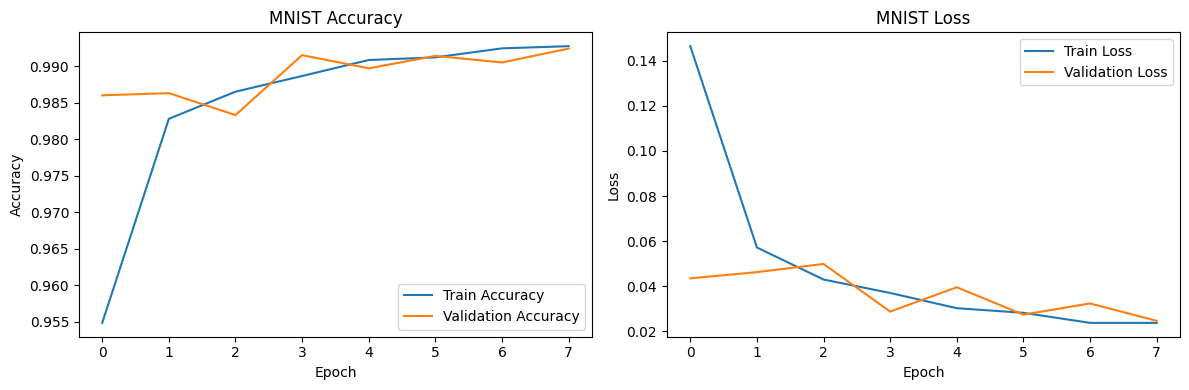

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['accuracy'], label='Train Accuracy')
plt.plot(history_mnist.history['val_accuracy'], label='Validation Accuracy')
plt.title('MNIST Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['loss'], label='Train Loss')
plt.plot(history_mnist.history['val_loss'], label='Validation Loss')
plt.title('MNIST Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()